<a href="https://colab.research.google.com/github/mateosanlu/MachineLearning/blob/main/ML_K-Means_SegInmuebles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# LABORATORIO: Segmentación de inmuebles en arriendo
# Algoritmo no supervisado: K-Means
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


In [ ]:
# ============================================================
# 1. Cargar dataset
# ============================================================

from google.colab import files
import pandas as pd

files.upload()

# Intentamos leer con decodificación utf-8-sig para manejar posibles BOMs o corregimos codificación básica
try:
    df = pd.read_csv("DATASET_INmuebles.csv", sep=";", encoding="utf-8-sig")
except Exception:
    df = pd.read_csv("DATASET_INmuebles.csv", sep=";", encoding="latin1")

# Limpiamos los nombres de las columnas eliminando caracteres extraños de codificación
df.columns = df.columns.str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('utf-8')

# Reemplazamos nombres para que coincidan con la normalización (sin tildes ni caracteres especiales)
# 'Area m2' en lugar de 'Ãrea mÂ²' o 'Área m²'
df = df.rename(columns={
    'Area m2': 'Area m2',
    'Area m': 'Area m2',
    'Area': 'Area m2'
}, errors='ignore')

# El identificador real en el archivo es "Inmueble"
ids = df["Inmueble"]

# Identificamos el nombre exacto de la columna de área
col_area = [c for c in df.columns if 'rea' in c or 'Area' in c][0]
col_precio = [c for c in df.columns if 'Precio' in c or 'precio' in c][0]
col_habitaciones = [c for c in df.columns if 'Habitaciones' in c or 'habitaciones' in c][0]
col_estrato = [c for c in df.columns if 'Estrato' in c or 'estrato' in c][0]
col_localidad = [c for c in df.columns if 'Localidad' in c or 'localidad' in c][0]

variables_numericas = [
    "Inmueble",
    col_area,
    col_habitaciones,
    col_estrato,
    col_precio
]

variables_categoricas = [col_localidad]

X = df[variables_numericas + variables_categoricas]

print("Columnas detectadas y limpiadas:", list(df.columns))
print("\nDataset original:")
print(df.head())

Saving DATASET_INmuebles.csv to DATASET_INmuebles.csv
Columnas detectadas y limpiadas: ['Inmueble', 'Area m2', 'Habitaciones', 'Estrato', 'Precio arriendo', 'Banos', 'Antig[uedad', 'Localidad', 'Tipo Inmueble', 'Estrato.1']

Dataset original:
  Inmueble  Area m2  Habitaciones  Estrato Precio arriendo  Banos  \
0       I1       69             2        2       1;413;951      2   
1       I2       39             1        2       1;006;165      2   
2       I3      142             5        5       8;570;904      1   
3       I4       62             3        4       3;678;698      1   
4       I5       58             1        3         875;729      1   

   Antig[uedad  Localidad  Tipo Inmueble  Estrato.1  
0           11       Suba           Apto          2  
1           10  Chapinero           Casa          3  
2            8    Usaquén  ApartaEstudio          4  
3           12       Suba           Apto          3  
4           12  Chapinero           Casa          4  


In [ ]:
# ============================================================
# 2. Seleccionar variables para clustering
# ============================================================

# Creamos una copia para evitar advertencias de asignación (SettingWithCopyWarning)
import pandas as pd

# Primero, limpiamos la columna de precios que tiene caracteres no numéricos como ';' o puntos
if df["Precio arriendo"].dtype == 'object':
    # Eliminamos cualquier caracter que no sea dígito
    df["Precio arriendo"] = df["Precio arriendo"].astype(str).str.replace(";", "").str.replace(".", "")
    df["Precio arriendo"] = pd.to_numeric(df["Precio arriendo"], errors='coerce')

# Seleccionamos las columnas con sus nombres exactos en el DataFrame
X = df[[
    "Area m2",
    "Habitaciones",
    "Estrato",
    "Precio arriendo"
]].copy()

# Eliminamos filas que puedan contener valores nulos tras la conversión
X = X.dropna()


In [ ]:
# ============================================================
# 3. Escalamiento de datos
# ============================================================

# K-Means usa distancias.
# Por eso es importante escalar los datos,
# ya que el precio tiene valores mucho más grandes que las otras variables.

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)



In [ ]:
# ============================================================
# 4. Aplicar K-Means
# ============================================================

# Vamos a crear 3 grupos de inmuebles:
# Cluster 0, Cluster 1 y Cluster 2

modelo = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

modelo.fit(X_scaled)

# Agregar el cluster al dataframe original
df["cluster"] = modelo.labels_

print("\nDataset con clusters asignados:")
print(df)



Dataset con clusters asignados:
    Inmueble  Area m2  Habitaciones  Estrato  Precio arriendo  Banos  \
0         I1       69             2        2          1413951      2   
1         I2       39             1        2          1006165      2   
2         I3      142             5        5          8570904      1   
3         I4       62             3        4          3678698      1   
4         I5       58             1        3           875729      1   
..       ...      ...           ...      ...              ...    ...   
995     I996      100             3        6          4265244      1   
996     I997      217             5        5          8752410      2   
997     I998       65             2        4          3851284      2   
998     I999       35             2        2          1166105      2   
999    I1000       59             1        2           753517      1   

     Antig[uedad  Localidad  Tipo Inmueble  Estrato.1  cluster  
0             11       Suba          

In [ ]:
# ============================================================
# 5. Ver centroides
# ============================================================

centroides = modelo.cluster_centers_

print("\nCentroides escalados:")
print(centroides)

# Para interpretar mejor los centroides,
# los devolvemos a la escala original.
centroides_originales = scaler.inverse_transform(centroides)

df_centroides = pd.DataFrame(
    centroides_originales,
    columns=[
        "Area m2",
        "Habitaciones",
        "Estrato",
        "Precio arriendo"
    ]
)

print("\nCentroides en escala original:")
print(df_centroides)


Centroides escalados:
[[-0.87045748 -0.8906935  -1.02062996 -0.88789714]
 [ 1.70499087  1.00775759  1.09204118  1.13207473]
 [ 0.44997483  1.11551757  1.12199382  1.07091811]
 [-0.21587118 -0.13788507  0.04542508 -0.21870888]]

Centroides en escala original:
      Area m2  Habitaciones   Estrato  Precio arriendo
0   49.658711      1.525060  2.501193     1.469202e+06
1  188.921053      3.952632  5.510526     6.392509e+06
2  121.058511      4.090426  5.553191     6.243451e+06
3   85.054187      2.487685  4.019704     3.100224e+06


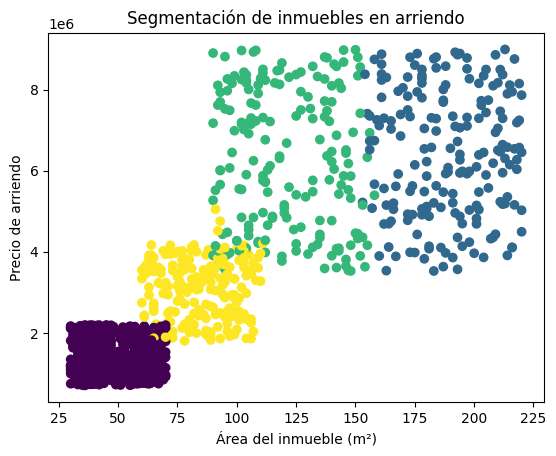

In [ ]:
# ============================================================
# 6. Visualización básica
# ============================================================

plt.scatter(
    df["Area m2"],
    df["Precio arriendo"],
    c=df["cluster"]
)

plt.xlabel("Área del inmueble (m²)")
plt.ylabel("Precio de arriendo")
plt.title("Segmentación de inmuebles en arriendo")
plt.show()

In [ ]:
# ============================================================
# 7. Resumen por cluster
# ============================================================

resumen = df.groupby("cluster")[
    [
        "Area m2",
        "Habitaciones",
        "Estrato",
        "Precio arriendo"
    ]
].mean()

print("\nResumen promedio por cluster:")
print(resumen)


Resumen promedio por cluster:
            Area m2  Habitaciones   Estrato  Precio arriendo
cluster                                                     
0         49.658711      1.525060  2.501193     1.469202e+06
1        188.921053      3.952632  5.510526     6.392509e+06
2        121.058511      4.090426  5.553191     6.243451e+06
3         85.054187      2.487685  4.019704     3.100224e+06
